[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Chu kỳ biến động chiếm ưu thế: khoảng 260.0 ngày


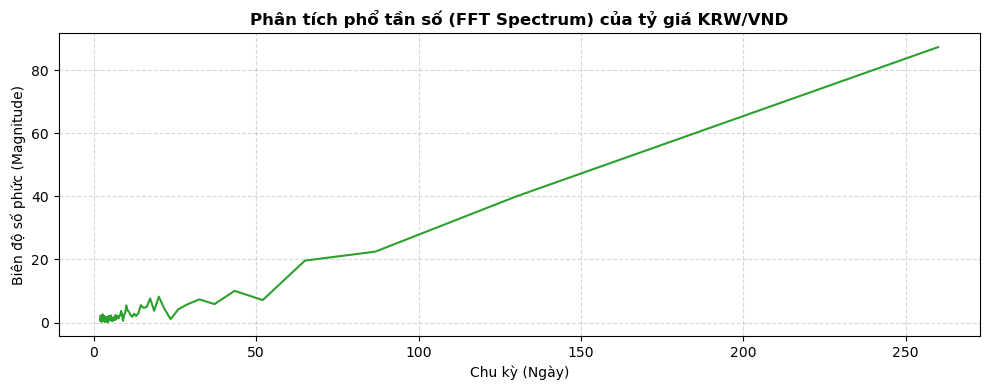

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# Lấy dữ liệu tỷ giá như trước
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()

# Khử xu hướng (Detrend) để tập trung vào dao động chu kỳ
prices_detrended = prices - np.polyval(np.polyfit(np.arange(len(prices)), prices, 1), np.arange(len(prices)))

# 1. Áp dụng Biến đổi Fourier (FFT) sử dụng số phức
fft_values = np.fft.fft(prices_detrended.values)
frequencies = np.fft.fftfreq(len(prices_detrended))

# Lọc các tần số dương
positive_mask = frequencies > 0
f_pos = frequencies[positive_mask]
fft_magnitude = np.abs(fft_values[positive_mask])  # Biên độ của số phức
fft_phase = np.angle(fft_values[positive_mask])     # Pha của số phức (góc lệch pha)

# Tìm chu kỳ chiếm ưu thế (tính bằng số ngày)
dominant_freq = f_pos[np.argmax(fft_magnitude)]
dominant_period = 1 / dominant_freq

print(f"Chu kỳ biến động chiếm ưu thế: khoảng {dominant_period:.1f} ngày")

# 2. Vẽ phổ biên độ từ số phức FFT
plt.figure(figsize=(10, 4))
plt.plot(1 / f_pos, fft_magnitude, color="#2ca02c")
plt.title("Phân tích phổ tần số (FFT Spectrum) của tỷ giá KRW/VND", fontsize=12, fontweight="bold")
plt.xlabel("Chu kỳ (Ngày)", fontsize=10)
plt.ylabel("Biên độ số phức (Magnitude)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Chu kỳ ngắn hạn chiếm ưu thế thực sự: khoảng 2.6 ngày


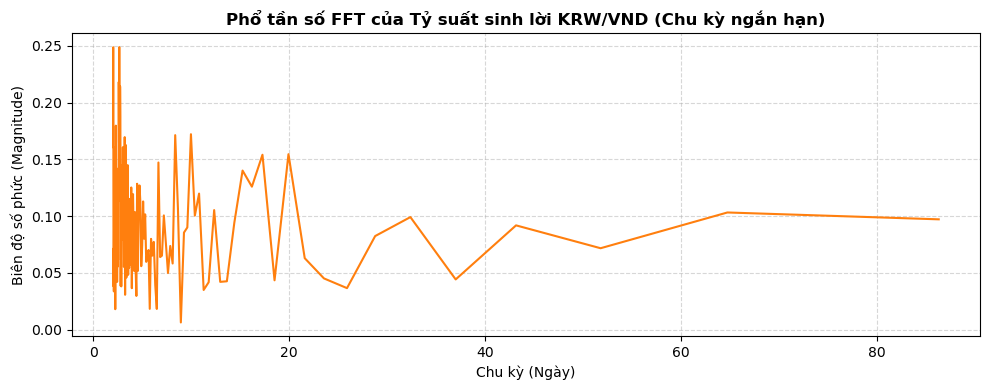

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# Lấy lại dữ liệu
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()

# 1. Chuyển sang Log Returns để loại bỏ xu hướng tăng dài hạn (detrending tự nhiên)
returns = np.log(prices / prices.shift(1)).dropna()

# 2. Áp dụng Biến đổi Fourier (FFT) trên số phức của returns
fft_values = np.fft.fft(returns.values)
frequencies = np.fft.fftfreq(len(returns))

positive_mask = frequencies > 0
f_pos = frequencies[positive_mask]
fft_magnitude = np.abs(fft_values[positive_mask])

# 3. Lọc chỉ xem xét các chu kỳ dưới 90 ngày (loại bỏ nhiễu chu kỳ quá dài)
valid_mask = (1 / f_pos) <= 90
periods = (1 / f_pos)[valid_mask]
mags = fft_magnitude[valid_mask]

# Tìm chu kỳ ngắn hạn mạnh nhất
dominant_period = periods[np.argmax(mags)]
print(f"Chu kỳ ngắn hạn chiếm ưu thế thực sự: khoảng {dominant_period:.1f} ngày")

# 4. Vẽ biểu đồ phổ tần số sau khi đã xử lý
plt.figure(figsize=(10, 4))
plt.plot(periods, mags, color="#ff7f0e", linewidth=1.5)
plt.title(
    "Phổ tần số FFT của Tỷ suất sinh lời KRW/VND (Chu kỳ ngắn hạn)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Chu kỳ (Ngày)", fontsize=10)
plt.ylabel("Biên độ số phức (Magnitude)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


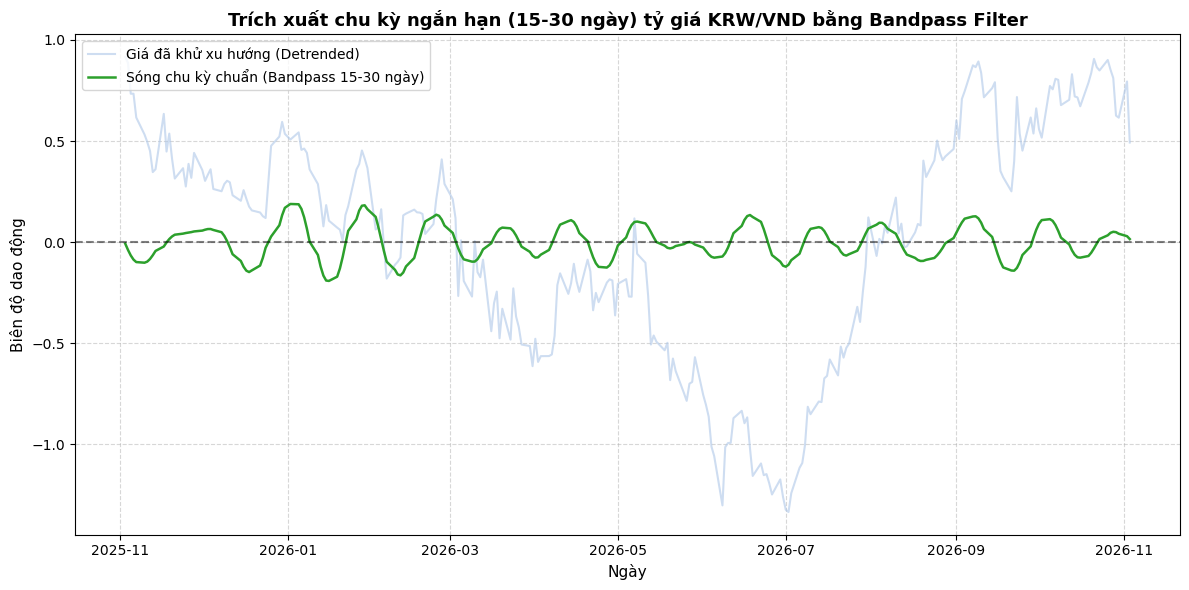

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt
import yfinance as yf

# 1. Tải dữ liệu KRW/VND
print("Đang tải dữ liệu tỷ giá...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()


# 2. Khử xu hướng tuyến tính (Detrend) để loại bỏ trend dài hạn 1 năm
def detrend_series(s):
  x = np.arange(len(s))
  coeffs = np.polyfit(x, s.values, 1)
  trend = np.polyval(coeffs, x)
  return s - trend


detrended_prices = detrend_series(prices)


# 3. Thiết lập Butterworth Bandpass Filter
def butter_bandpass(lowcut, highcut, fs=1.0, order=4):
  nyq = 0.5 * fs
  low = lowcut / nyq
  high = highcut / nyq
  b, a = butter(order, [low, high], btype="band")
  return b, a


def bandpass_filter(data, lowcut, highcut, fs=1.0, order=4):
  b, a = butter_bandpass(lowcut, highcut, fs, order=order)
  y = filtfilt(b, a, data)
  return y


# Định nghĩa khoảng chu kỳ muốn giữ lại: Từ 15 đến 30 ngày
fs = 1.0  # Tần số lấy mẫu (1 ngày)
lowcut = 1.0 / 30.0  # Chu kỳ tối đa (30 ngày)
highcut = 1.0 / 15.0  # Chu kỳ tối thiểu (15 ngày)

filtered_cycle = bandpass_filter(
    detrended_prices.values, lowcut, highcut, fs=fs, order=4
)

# 4. Trực quan hóa kết quả
plt.figure(figsize=(12, 6))
plt.plot(
    prices.index,
    detrended_prices,
    label="Giá đã khử xu hướng (Detrended)",
    color="#aec7e8",
    alpha=0.6,
)
plt.plot(
    prices.index,
    filtered_cycle,
    label="Sóng chu kỳ chuẩn (Bandpass 15-30 ngày)",
    color="#2ca02c",
    linewidth=1.8,
)

plt.axhline(0, color="black", linestyle="--", alpha=0.5)
plt.title(
    "Trích xuất chu kỳ ngắn hạn (15-30 ngày) tỷ giá KRW/VND bằng Bandpass Filter",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Ngày", fontsize=11)
plt.ylabel("Biên độ dao động", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


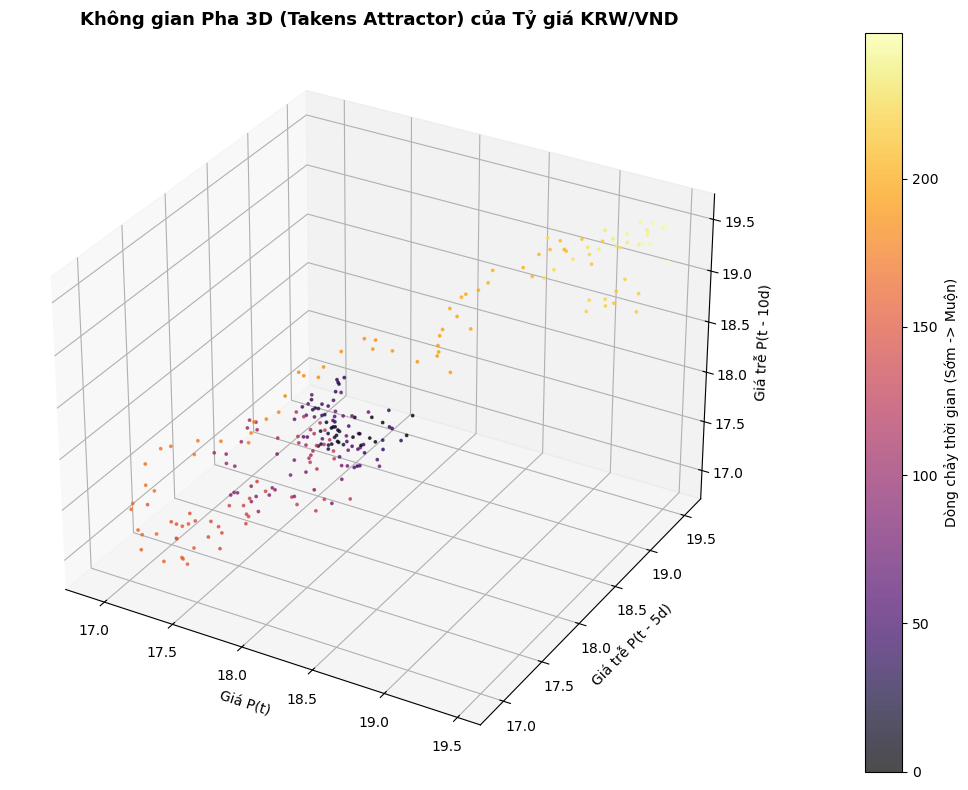

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu tỷ giá...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna().values

# 2. Áp dụng Định lý Takens để nhúng vào không gian pha 3D
tau = 5  # Độ trễ thời gian (time delay)
x_t = prices[:-2 * tau]
x_t_tau = prices[tau:-tau]
x_t_2tau = prices[2 * tau :]

# 3. Vẽ biểu đồ không gian pha 3D (Strange Attractor)
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(projection="3d")

# Tô màu theo dòng chảy thời gian (từ tối/cũ đến sáng/mới)
sc = ax.scatter(
    x_t,
    x_t_tau,
    x_t_2tau,
    c=np.arange(len(x_t)),
    cmap="inferno",
    s=3,
    alpha=0.7,
)

ax.set_title(
    "Không gian Pha 3D (Takens Attractor) của Tỷ giá KRW/VND",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Giá P(t)", fontsize=10)
ax.set_ylabel(f"Giá trễ P(t - {tau}d)", fontsize=10)
ax.set_zlabel(f"Giá trễ P(t - {2*tau}d)", fontsize=10)

cbar = plt.colorbar(sc, pad=0.1)
cbar.set_label("Dòng chảy thời gian (Sớm -> Muộn)")

plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


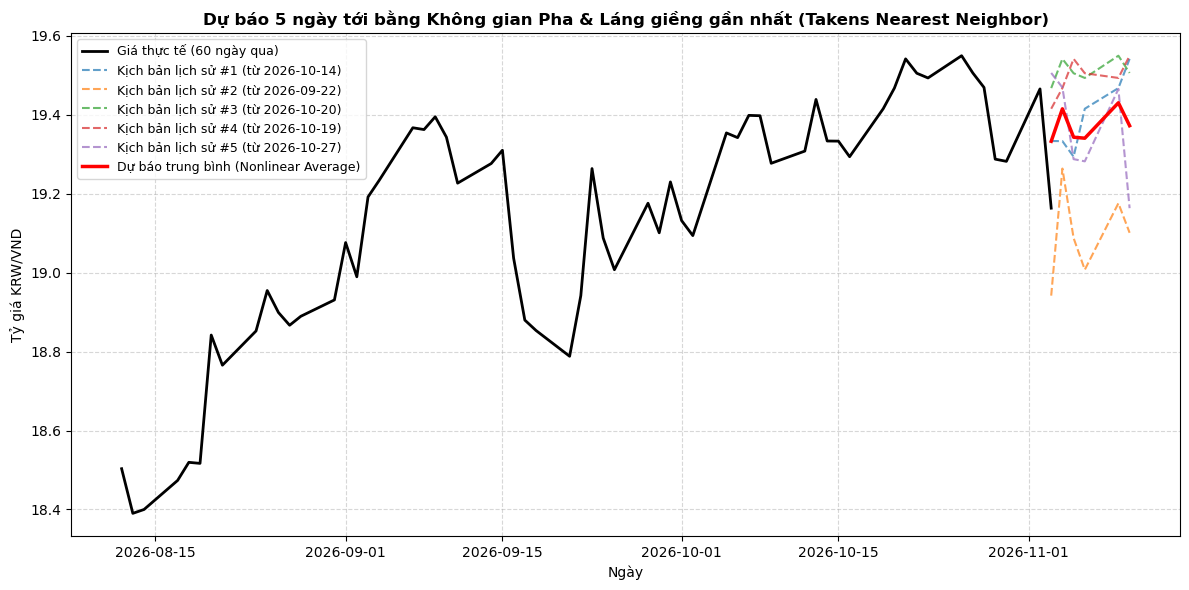

Dự báo tỷ giá sau 5 ngày: 19.37 (Biến động kỳ vọng: +1.09%)


In [6]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu tỷ giá...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values

# 2. Xây dựng không gian pha với độ trễ tau = 5
tau = 5
embed_dim = 3
N = len(prices_vals)

# Tạo ma trận trạng thái pha (Phase Space Matrix)
# Mỗi hàng là một vector trạng thái: [P(t), P(t-tau), P(t-2*tau)]
valid_indices = range(2 * tau, N - 5)  # Chừa lại 5 ngày cuối để dự báo tương lai
phase_space = np.array([
    [prices_vals[i], prices_vals[i - tau], prices_vals[i - 2 * tau]]
    for i in valid_indices
])

# Trạng thái hiện tại của thị trường (ngày mới nhất)
current_state = np.array(
    [prices_vals[-1], prices_vals[-1 - tau], prices_vals[-1 - 2 * tau]]
)

# 3. Tìm các "láng giềng gần nhất" (Nearest Neighbors) trong không gian pha
from scipy.spatial import KDTree

tree = KDTree(phase_space)
# Tìm 5 điểm trong lịch sử có hình thái không gian giống hiện tại nhất (bỏ qua chính nó nếu trùng)
distances, indices = tree.query(current_state, k=6)

# Lọc bỏ điểm gần nhất chính là hiện tại (khoảng cách = 0)
neighbors = [valid_indices[i] for i in indices if valid_indices[i] < N - 5][:5]

# 4. Dự báo đường đi trong 5 ngày tới dựa trên các láng giềng lịch sử
forecast_horizon = 5
future_paths = []

plt.figure(figsize=(12, 6))
# Vẽ lịch sử gần đây để dễ quan sát
plt.plot(
    prices.index[-60:],
    prices.values[-60:],
    label="Giá thực tế (60 ngày qua)",
    color="black",
    linewidth=2,
)

for rank, idx in enumerate(neighbors):
  # Lấy chuỗi giá thực tế trong 5 ngày tiếp theo sau thời điểm lịch sử đó
  path_dates = prices.index[idx : idx + forecast_horizon + 1]
  path_prices = prices.values[idx : idx + forecast_horizon + 1]

  # Dịch chuyển mốc thời gian về hiện tại để so sánh
  shifted_dates = pd.date_range(
      start=prices.index[-1], periods=forecast_horizon + 1, freq="B"
  )

  future_paths.append(path_prices)
  plt.plot(
      shifted_dates,
      path_prices,
      linestyle="--",
      alpha=0.7,
      label=f"Kịch bản lịch sử #{rank+1} (từ {prices.index[idx].strftime('%Y-%m-%d')})",
  )

# Tính trung bình dự báo từ các láng giềng
avg_future_path = np.mean(future_paths, axis=0)
current_date_extended = pd.date_range(
    start=prices.index[-1], periods=forecast_horizon + 1, freq="B"
)

plt.plot(
    current_date_extended,
    avg_future_path,
    color="red",
    linewidth=2.5,
    label="Dự báo trung bình (Nonlinear Average)",
)

plt.title(
    "Dự báo 5 ngày tới bằng Không gian Pha & Láng giềng gần nhất (Takens"
    " Nearest Neighbor)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Ngày", fontsize=10)
plt.ylabel("Tỷ giá KRW/VND", fontsize=10)
plt.legend(loc="upper left", fontsize=9)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# In ra mức thay đổi kỳ vọng
expected_change = (avg_future_path[-1] - prices.values[-1]) / prices.values[
    -1
] * 100
print(
    f"Dự báo tỷ giá sau 5 ngày: {avg_future_path[-1]:.2f} (Biến động kỳ"
    f" vọng: {expected_change:+.2f}%)"
)

In [7]:
import numpy as np
import yfinance as yf

# 1. Tải dữ liệu
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna().values


# 2. Hàm ước tính đơn giản Số mũ Lyapunov cực đại từ không gian pha
def compute_approx_lyapunov(series, tau=5, dim=3):
  N = len(series)
  # Xây dựng không gian pha
  M = N - (dim - 1) * tau
  phase_space = np.array(
      [series[i : i + dim * tau : tau] for i in range(M)]
  )

  divergences = []
  # Tìm láng giềng gần nhất cho mỗi điểm và theo dõi độ tách xa sau k bước
  from scipy.spatial import KDTree

  tree = KDTree(phase_space)

  for i in range(M - 10):
    # Tìm điểm láng giềng gần nhất (không tính chính nó)
    distances, indices = tree.query(phase_space[i], k=2)
    nn_idx = indices[1]
    initial_dist = distances[1]

    if initial_dist > 0 and (i + 5 < M) and (nn_idx + 5 < M):
      # Đo khoảng cách sau 5 bước thời gian
      later_dist = np.linalg.norm(phase_space[i + 5] - phase_space[nn_idx + 5])
      if later_dist > 0:
        divergences.append(np.log(later_dist / initial_dist) / 5)

  return np.mean(divergences) if divergences else 0.0


mle = compute_approx_lyapunov(prices)
print(f"Hệ số Lyapunov cực đại ước tính (MLE): {mle:.4f}")

if mle > 0:
  print(
      "Kết luận toán học: Hệ thống mang tính HỖN LOẠN (Chaotic). Dự báo dài"
      " hạn là bất khả thi, chỉ nên giao dịch ngắn hạn."
  )
else:
  print("Kết luận toán học: Hệ thống mang tính TRẬT TỰ / HỘI TỤ.")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

Hệ số Lyapunov cực đại ước tính (MLE): 0.1396
Kết luận toán học: Hệ thống mang tính HỖN LOẠN (Chaotic). Dự báo dài hạn là bất khả thi, chỉ nên giao dịch ngắn hạn.


Đang tải dữ liệu tỷ giá...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed



Chiều tương quan Fractal (D2) ước tính: 1.7478
Ý nghĩa: Cấu trúc không gian pha của tỷ giá không phải số nguyên mà là dạng Fractal (1.75 chiều).


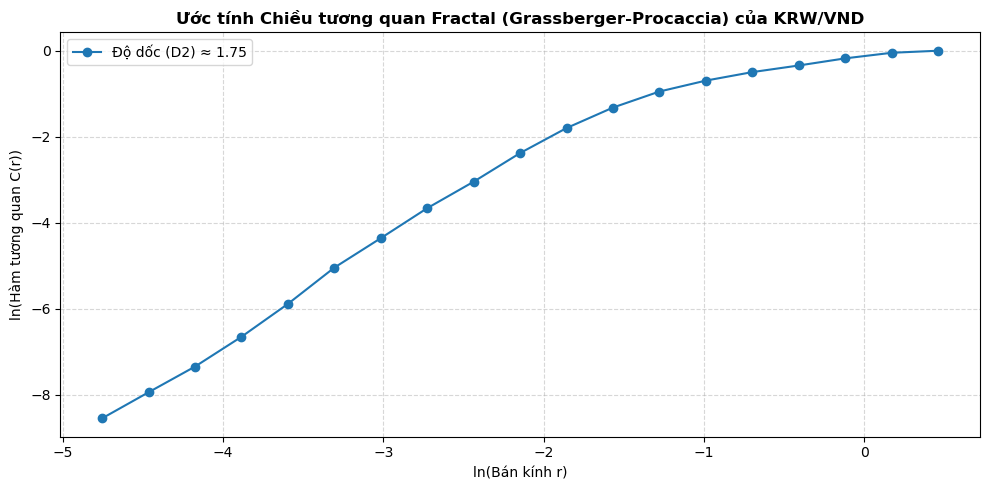

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import yfinance as yf
from scipy.spatial.distance import pdist

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu tỷ giá...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna().values

# Chuẩn hóa dữ liệu về khoảng [0, 1] để tính khoảng cách chuẩn xác
prices_norm = (prices - np.min(prices)) / (np.max(prices) - np.min(prices))


# 2. Xây dựng không gian pha nhúng (Embedding)
def embed_series(series, tau=5, dim=3):
  N = len(series)
  M = N - (dim - 1) * tau
  return np.array([series[i : i + dim * tau : tau] for i in range(M)])


dim = 3
tau = 5
phase_space = embed_series(prices_norm, tau=tau, dim=dim)


# 3. Tính hàm tương quan C(r) theo Grassberger-Procaccia
def compute_correlation_dimension(phase_space):
  # Tính khoảng cách đôi một giữa tất cả các điểm trong không gian pha
  distances = pdist(phase_space, metric="euclidean")

  # Tạo dải bán kính r từ nhỏ đến lớn
  r_values = np.logspace(
      np.log10(np.min(distances[distances > 0])),
      np.log10(np.max(distances)),
      num=20,
  )
  c_r = []

  total_pairs = len(distances)
  for r in r_values:
    # Đếm tỷ lệ các cặp điểm có khoảng cách nhỏ hơn r
    count = np.sum(distances < r)
    c_r.append(count / total_pairs)

  r_values = np.array(r_values)
  c_r = np.array(c_r)

  # Lọc bỏ các giá trị bằng 0 để tránh lỗi log
  mask = c_r > 0
  log_r = np.log(r_values[mask])
  log_c = np.log(c_r[mask])

  # Tính độ dốc (slope) qua hồi quy tuyến tính trong vùng tỷ lệ hội tụ (Scaling region)
  slope, _ = np.polyfit(log_r, log_c, 1)

  return r_values[mask], c_r[mask], slope


r_vals, c_vals, d2 = compute_correlation_dimension(phase_space)

print(f"\nChiều tương quan Fractal (D2) ước tính: {d2:.4f}")
print(
    "Ý nghĩa: Cấu trúc không gian pha của tỷ giá không phải số nguyên mà là"
    f" dạng Fractal ({d2:.2f} chiều)."
)

# 4. Trực quan hóa đường cong Scaling Log-Log
plt.figure(figsize=(10, 5))
plt.plot(
    np.log(r_vals),
    np.log(c_vals),
    marker="o",
    color="#1f77b4",
    label=f"Độ dốc (D2) ≈ {d2:.2f}",
)
plt.title(
    "Ước tính Chiều tương quan Fractal (Grassberger-Procaccia) của KRW/VND",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("ln(Bán kính r)", fontsize=10)
plt.ylabel("ln(Hàm tương quan C(r))", fontsize=10)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed



--- KẾT QUẢ BACKTEST PIPELINE PHI TUYẾN ---
Lợi nhuận Buy & Hold: 3.97%
Lợi nhuận Chiến lược Không gian Pha (Chaos Filter): 0.02%


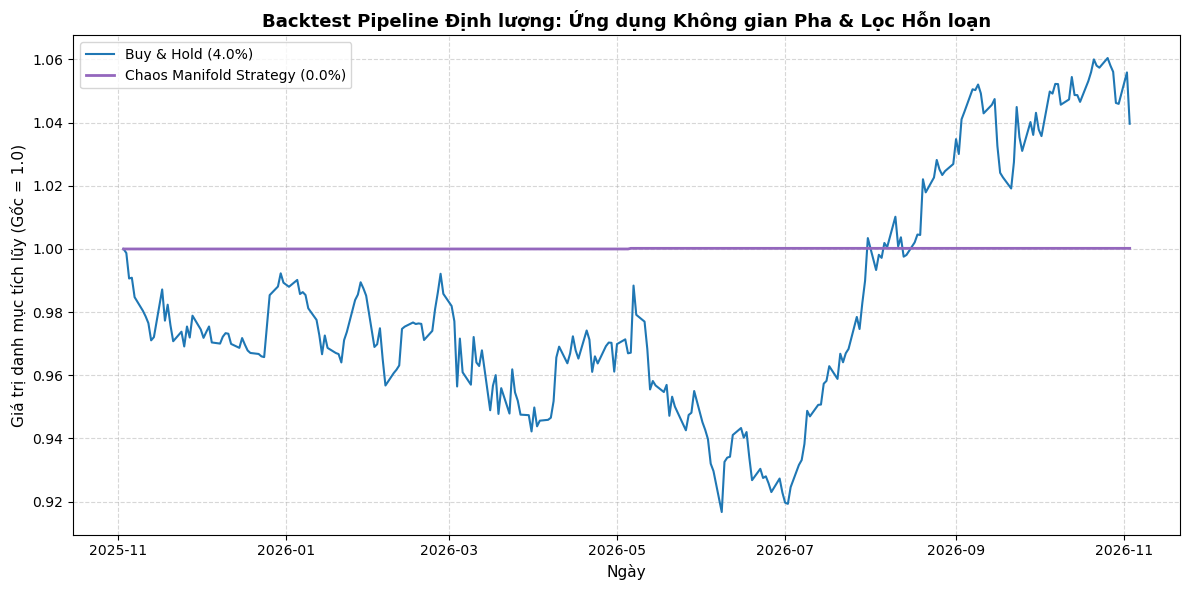

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu tỷ giá...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values

# 2. Xây dựng Không gian Pha (Embedding Dimension = 3, Tau = 5)
tau = 5
dim = 3
N = len(prices_vals)

# Tạo ma trận trạng thái pha
valid_indices = range((dim - 1) * tau, N - 5)
phase_space = np.array(
    [
        [prices_vals[i], prices_vals[i - tau], prices_vals[i - 2 * tau]]
        for i in valid_indices
    ]
)

tree = KDTree(phase_space)

# 3. Chạy Backtest vòng lặp thời gian thực (Walk-forward Simulation)
signals = np.zeros(N)
forecast_horizon = 5

for idx, i in enumerate(valid_indices):
  if i >= N - forecast_horizon:
    break

  current_state = phase_space[idx]

  # Tìm 5 láng giềng gần nhất trong lịch sử (bỏ qua chính nó)
  distances, indices = tree.query(current_state, k=6)

  # Lọc các điểm láng giềng hợp lệ trong quá khứ
  valid_neighbors = []
  valid_dists = []
  for d, n_idx in zip(distances[1:], indices[1:]):
    hist_pos = valid_indices[n_idx]
    if hist_pos < i - 10:  # Tránh lấy dữ liệu quá gần hiện tại (leakage)
      valid_neighbors.append(hist_pos)
      valid_dists.append(d)

  # ĐIỀU KIỆN "QUÁI DỊ" (Chaos Filter): Chỉ giao dịch khi độ cô lập nhỏ (khoảng cách láng giềng dưới ngưỡng an toàn)
  if valid_dists and np.mean(valid_dists) < 0.05:  # Ngưỡng hội tụ manifold
    future_returns = []
    for h_pos in valid_neighbors[:3]:  # Lấy top 3 láng giềng gần nhất
      ret = (
          prices_vals[h_pos + forecast_horizon] - prices_vals[h_pos]
      ) / prices_vals[h_pos]
      future_returns.append(ret)

    avg_expected_return = np.mean(future_returns)

    # Phát tín hiệu: Nếu kỳ vọng tăng -> Mua (1), giảm -> Đứng ngoài/Bán (-1)
    if avg_expected_return > 0.002:  # Kỳ vọng tăng > 0.2%
      signals[i] = 1
    elif avg_expected_return < -0.002:
      signals[i] = -1
    else:
      signals[i] = 0
  else:
    signals[i] = 0  # Thị trường quá hỗn loạn, đứng ngoài bảo toàn vốn

# 4. Đánh giá hiệu suất danh mục
df_backtest = pd.DataFrame(index=prices.index)
df_backtest["Price"] = prices
df_backtest["Daily_Return"] = prices.pct_change()
df_backtest["Signal"] = signals

# Dịch chuyển tín hiệu để chống Look-ahead Bias
df_backtest["Strategy_Return"] = (
    df_backtest["Signal"].shift(1) * df_backtest["Daily_Return"]
)

df_backtest["Buy_Hold"] = (
    1 + df_backtest["Daily_Return"].fillna(0)
).cumprod()
df_backtest["Strategy"] = (
    1 + df_backtest["Strategy_Return"].fillna(0)
).cumprod()

bh_total = (df_backtest["Buy_Hold"].iloc[-1] - 1) * 100
strat_total = (df_backtest["Strategy"].iloc[-1] - 1) * 100

print(f"\n--- KẾT QUẢ BACKTEST PIPELINE PHI TUYẾN ---")
print(f"Lợi nhuận Buy & Hold: {bh_total:.2f}%")
print(f"Lợi nhuận Chiến lược Không gian Pha (Chaos Filter): {strat_total:.2f}%")

# 5. Vẽ biểu đồ so sánh
plt.figure(figsize=(12, 6))
plt.plot(
    df_backtest.index,
    df_backtest["Buy_Hold"],
    label=f"Buy & Hold ({bh_total:.1f}%)",
    color="#1f77b4",
    linewidth=1.5,
)
plt.plot(
    df_backtest.index,
    df_backtest["Strategy"],
    label=f"Chaos Manifold Strategy ({strat_total:.1f}%)",
    color="#9467bd",
    linewidth=2,
)
plt.title(
    "Backtest Pipeline Định lượng: Ứng dụng Không gian Pha & Lọc Hỗn loạn",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Ngày", fontsize=11)
plt.ylabel("Giá trị danh mục tích lũy (Gốc = 1.0)", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed



--- KẾT QUẢ KIỂM CHỨNG GIẢ THUYẾT ---
Sai số dự báo trung bình (MAE) ở chế độ ÍT HỖN LOẠN: 0.1633
Sai số dự báo trung bình (MAE) ở chế độ HỖN LOẠN CAO: 0.1116


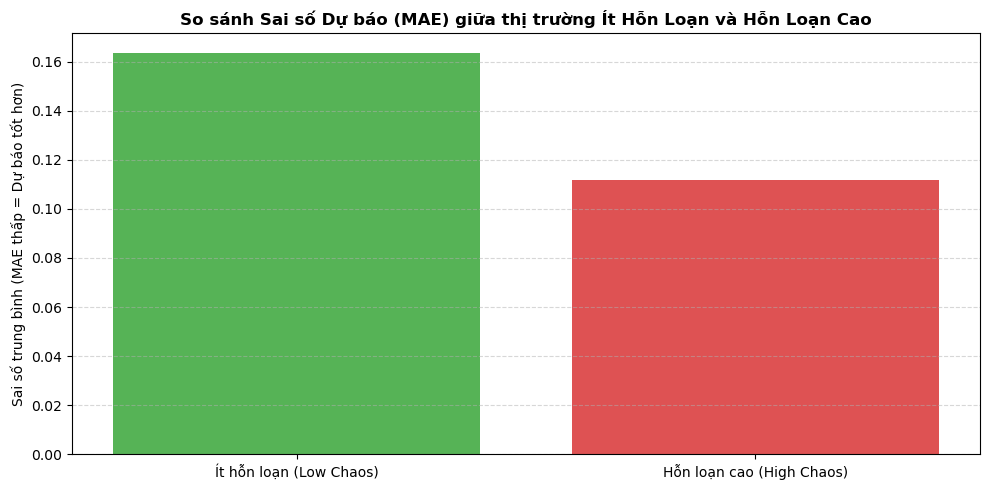

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu tỷ giá...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values

tau = 5
dim = 3
N = len(prices_vals)

# Tạo không gian pha toàn cục
valid_indices = range((dim - 1) * tau, N - 5)
phase_space = np.array(
    [
        [prices_vals[i], prices_vals[i - tau], prices_vals[i - 2 * tau]]
        for i in valid_indices
    ]
)
tree = KDTree(phase_space)

# 2. Đánh giá độ hỗn loạn cục bộ (Rolling Local Chaos Metric) qua độ phân tán láng giềng
window_size = 30
chaos_metrics = []
prediction_errors = []

forecast_horizon = 5

for idx, i in enumerate(valid_indices):
  if i >= N - forecast_horizon:
    break

  current_state = phase_space[idx]
  distances, indices = tree.query(current_state, k=6)

  # Lọc láng giềng hợp lệ trong quá khứ
  valid_dists = [
      d for d, n_idx in zip(distances[1:], indices[1:]) if valid_indices[n_idx] < i - 10
  ]

  if not valid_dists:
    continue

  # Chỉ số hỗn loạn cục bộ: Độ phân tán trung bình của các láng giềng gần nhất
  local_chaos = np.mean(valid_dists)
  chaos_metrics.append((i, local_chaos))

  # Tính dự báo 5 ngày tới bằng trung bình láng giềng
  future_paths = []
  for n_idx in indices[1:4]:
    h_pos = valid_indices[n_idx]
    if h_pos + forecast_horizon < N:
      future_paths.append(prices_vals[h_pos : h_pos + forecast_horizon + 1])

  if future_paths:
    avg_pred = np.mean(future_paths, axis=0)
    actual_path = prices_vals[i : i + forecast_horizon + 1]

    # Sai số dự báo thực tế (MAE trong 5 ngày)
    if len(avg_pred) == len(actual_path):
      mae = np.mean(np.abs(avg_pred - actual_path))
      prediction_errors.append((i, local_chaos, mae))

# 3. Phân tách thành 2 nhóm: Ít hỗn loạn vs Hỗn loạn cao
df_eval = pd.DataFrame(prediction_errors, columns=["Index", "Chaos_Score", "MAE"])
median_chaos = df_eval["Chaos_Score"].median()

low_chaos_group = df_eval[df_eval["Chaos_Score"] <= median_chaos]
high_chaos_group = df_eval[df_eval["Chaos_Score"] > median_chaos]

print("\n--- KẾT QUẢ KIỂM CHỨNG GIẢ THUYẾT ---")
print(
    f"Sai số dự báo trung bình (MAE) ở chế độ ÍT HỖN LOẠN: {low_chaos_group['MAE'].mean():.4f}"
)
print(
    f"Sai số dự báo trung bình (MAE) ở chế độ HỖN LOẠN CAO: {high_chaos_group['MAE'].mean():.4f}"
)

# 4. Trực quan hóa
plt.figure(figsize=(10, 5))
plt.bar(
    ["Ít hỗn loạn (Low Chaos)", "Hỗn loạn cao (High Chaos)"],
    [low_chaos_group["MAE"].mean(), high_chaos_group["MAE"].mean()],
    color=["#2ca02c", "#d62728"],
    alpha=0.8,
)
plt.title(
    "So sánh Sai số Dự báo (MAE) giữa thị trường Ít Hỗn Loạn và Hỗn Loạn Cao",
    fontsize=12,
    fontweight="bold",
)
plt.ylabel("Sai số trung bình (MAE thấp = Dự báo tốt hơn)", fontsize=10)
plt.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu lịch sử để kiểm chứng sai số...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Đang chạy mô phỏng dự báo từng ngày trong quá khứ (Rolling Out-of-Sample)...

--- KẾT QUẢ ĐÁNH GIÁ ĐỘ CHÊNH LỆCH DỰ BÁO (5 NGÀY TỚI) ---
Sai số tuyệt đối trung bình (MAE): 0.2730
Sai số căn bậc hai trung bình (RMSE): 0.3310
Sai số phần trăm tuyệt đối trung bình (MAPE): 1.5247%


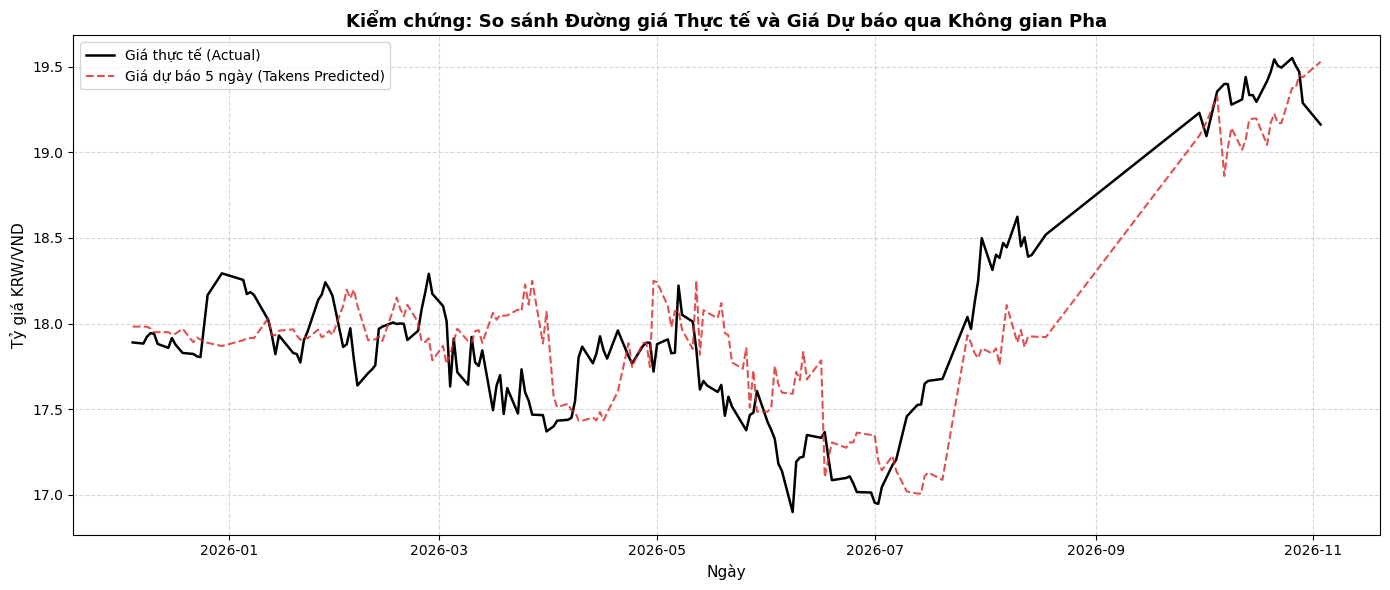

In [12]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu lịch sử để kiểm chứng sai số...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values

tau = 5
dim = 3
N = len(prices_vals)
forecast_horizon = 5

valid_indices = range((dim - 1) * tau, N - forecast_horizon)

# 2. Vòng lặp Out-of-Sample: Dự báo từng ngày trong quá khứ và so với thực tế
actual_values = []
predicted_values = []
eval_dates = []

print(
    "Đang chạy mô phỏng dự báo từng ngày trong quá khứ (Rolling"
    " Out-of-Sample)..."
)

for i in valid_indices:
  history_prices = prices_vals[: i + 1]
  min_history_len = (dim - 1) * tau + 1
  if len(history_prices) < min_history_len:
    continue

  hist_valid_indices = list(range((dim - 1) * tau, len(history_prices)))
  phase_space = np.array(
      [
          [
              history_prices[j],
              history_prices[j - tau],
              history_prices[j - 2 * tau],
          ]
          for j in hist_valid_indices
      ]
  )

  # Đảm bảo số lượng k láng giềng không vượt quá số điểm hiện có trong không gian pha
  if len(phase_space) < 3:
    continue

  tree = KDTree(phase_space)

  current_state = np.array(
      [history_prices[-1], history_prices[-1 - tau], history_prices[-1 - 2 * tau]]
  )

  k_neighbors = min(6, len(phase_space))
  distances, indices = tree.query(current_state, k=k_neighbors)

  # Xử lý trường hợp indices trả về dạng số nguyên đơn lẻ hoặc mảng
  if np.isscalar(indices):
    indices = [indices]
    distances = [distances]

  valid_neighbors = []
  for d, n_idx in zip(distances[1:], indices[1:]):
    if n_idx < len(hist_valid_indices):
      h_pos = hist_valid_indices[n_idx]
      if h_pos < len(history_prices) - forecast_horizon:
        valid_neighbors.append(h_pos)

  if len(valid_neighbors) >= 2:
    future_paths = []
    for h_pos in valid_neighbors[:3]:
      path = history_prices[h_pos : h_pos + forecast_horizon + 1]
      if len(path) == forecast_horizon + 1:
        future_paths.append(path)

    if future_paths:
      avg_path = np.mean(future_paths, axis=0)
      pred_val = avg_path[-1]
      actual_val = prices_vals[i + forecast_horizon]

      actual_values.append(actual_val)
      predicted_values.append(pred_val)
      eval_dates.append(prices.index[i + forecast_horizon])

# 3. Tính toán các chỉ số sai số (Metrics)
actual_values = np.array(actual_values)
predicted_values = np.array(predicted_values)

if len(actual_values) > 0:
  mae = np.mean(np.abs(predicted_values - actual_values))
  rmse = np.sqrt(np.mean((predicted_values - actual_values) ** 2))
  mape = (
      np.mean(np.abs((actual_values - predicted_values) / actual_values)) * 100
  )

  print(f"\n--- KẾT QUẢ ĐÁNH GIÁ ĐỘ CHÊNH LỆCH DỰ BÁO (5 NGÀY TỚI) ---")
  print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")
  print(f"Sai số căn bậc hai trung bình (RMSE): {rmse:.4f}")
  print(f"Sai số phần trăm tuyệt đối trung bình (MAPE): {mape:.4f}%")

  # 4. Trực quan hóa so sánh Giá thực tế vs Giá dự báo
  plt.figure(figsize=(14, 6))
  plt.plot(
      eval_dates,
      actual_values,
      label="Giá thực tế (Actual)",
      color="black",
      linewidth=1.8,
  )
  plt.plot(
      eval_dates,
      predicted_values,
      label="Giá dự báo 5 ngày (Takens Predicted)",
      color="#d62728",
      linestyle="--",
      linewidth=1.5,
      alpha=0.8,
  )
  plt.title(
      "Kiểm chứng: So sánh Đường giá Thực tế và Giá Dự báo qua Không gian Pha",
      fontsize=13,
      fontweight="bold",
  )
  plt.xlabel("Ngày", fontsize=11)
  plt.ylabel("Tỷ giá KRW/VND", fontsize=11)
  plt.legend(loc="upper left")
  plt.grid(True, linestyle="--", alpha=0.5)
  plt.tight_layout()
  plt.show()
else:
  print("Không đủ dữ liệu hợp lệ để chạy mô phỏng.")

Đang tải dữ liệu lịch sử để tối ưu hóa mô hình...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Đang chạy Grid Search tìm tham số tối ưu (tau, dim)...

=> TÌM THẤY THAM SỐ TỐI ƯU: tau = 2, dim = 2 (MAPE thử nghiệm: 1.35%)

Đang chạy mô phỏng Out-of-Sample với trọng số khoảng cách (Distance Weighting)...

--- KẾT QUẢ SAU KHI TỐI ƯU HÓA ---
Tham số chọn lọc: tau = 2, dim = 2
Sai số tuyệt đối trung bình (MAE): 0.2500
Sai số căn bậc hai trung bình (RMSE): 0.3030
Sai số phần trăm tuyệt đối trung bình (MAPE): 1.3865%


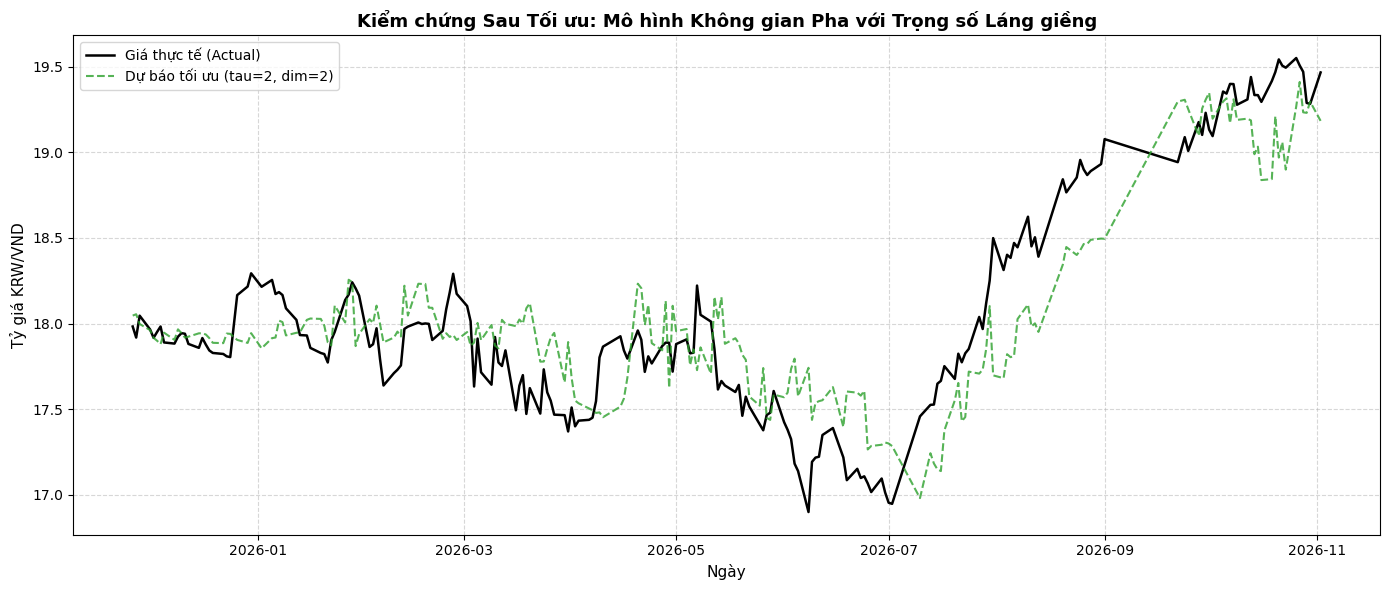

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu lịch sử để tối ưu hóa mô hình...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values
N = len(prices_vals)
forecast_horizon = 5

# 2. Grid Search tìm cặp tham số (tau, dim) tối ưu nhất
best_mape = float("inf")
best_tau, best_dim = 5, 3

tau_candidates = [2, 3, 5, 7]
dim_candidates = [2, 3, 4]

print("Đang chạy Grid Search tìm tham số tối ưu (tau, dim)...")
for t in tau_candidates:
  for d in dim_candidates:
    min_len = (d - 1) * t + forecast_horizon
    if N < min_len + 30:
      continue

    # Chạy thử nghiệm nhanh trên tập con để tìm tham số
    valid_indices = range((d - 1) * t, N - forecast_horizon)
    actuals, preds = [], []

    # Lấy mẫu ngẫu nhiên hoặc chạy bước nhảy để tối ưu tốc độ grid search
    for i in list(valid_indices)[::3]:
      history_prices = prices_vals[: i + 1]
      hist_valid_indices = list(range((d - 1) * t, len(history_prices)))
      phase_space = np.array(
          [
              [history_prices[j]]
              + [history_prices[j - k * t] for k in range(1, d)]
              for j in hist_valid_indices
          ]
      )

      if len(phase_space) < 3:
        continue

      tree = KDTree(phase_space)
      current_state = np.array(
          [history_prices[-1]]
          + [history_prices[-1 - k * t] for k in range(1, d)]
      )

      k_neighbors = min(5, len(phase_space))
      distances, indices = tree.query(current_state, k=k_neighbors)

      if np.isscalar(indices):
        indices = [indices]
        distances = [distances]

      valid_neighbors = []
      valid_dists = []
      for d_val, n_idx in zip(distances[1:], indices[1:]):
        if n_idx < len(hist_valid_indices):
          h_pos = hist_valid_indices[n_idx]
          if h_pos < len(history_prices) - forecast_horizon:
            valid_neighbors.append(h_pos)
            valid_dists.append(d_val)

      if len(valid_neighbors) >= 2:
        future_paths = []
        for h_pos in valid_neighbors[:3]:
          path = history_prices[h_pos : h_pos + forecast_horizon + 1]
          if len(path) == forecast_horizon + 1:
            future_paths.append(path)

        if future_paths:
          avg_path = np.mean(future_paths, axis=0)
          preds.append(avg_path[-1])
          actuals.append(prices_vals[i + forecast_horizon])

    if len(actuals) > 10:
      current_mape = (
          np.mean(np.abs((np.array(actuals) - np.array(preds)) / actuals)) * 100
      )
      if current_mape < best_mape:
        best_mape = current_mape
        best_tau = t
        best_dim = d

print(
    f"\n=> TÌM THẤY THAM SỐ TỐI ƯU: tau = {best_tau}, dim = {best_dim} (MAPE"
    f" thử nghiệm: {best_mape:.2f}%)"
)

# 3. Chạy kiểm chứng chính thức với Distance-Weighted Averaging và tham số tối ưu
tau = best_tau
dim = best_dim
valid_indices = range((dim - 1) * tau, N - forecast_horizon)

actual_values = []
predicted_values = []
eval_dates = []

print(
    "\nĐang chạy mô phỏng Out-of-Sample với trọng số khoảng cách (Distance"
    " Weighting)..."
)

for i in valid_indices:
  history_prices = prices_vals[: i + 1]
  min_history_len = (dim - 1) * tau + 1
  if len(history_prices) < min_history_len:
    continue

  hist_valid_indices = list(range((dim - 1) * tau, len(history_prices)))
  phase_space = np.array(
      [
          [history_prices[j]]
          + [history_prices[j - k * tau] for k in range(1, dim)]
          for j in hist_valid_indices
      ]
  )

  if len(phase_space) < 3:
    continue

  tree = KDTree(phase_space)
  current_state = np.array(
      [history_prices[-1]] + [history_prices[-1 - k * tau] for k in range(1, dim)]
  )

  k_neighbors = min(6, len(phase_space))
  distances, indices = tree.query(current_state, k=k_neighbors)

  if np.isscalar(indices):
    indices = [indices]
    distances = [distances]

  valid_neighbors = []
  weights = []
  for d_val, n_idx in zip(distances[1:], indices[1:]):
    if n_idx < len(hist_valid_indices):
      h_pos = hist_valid_indices[n_idx]
      if h_pos < len(history_prices) - forecast_horizon:
        valid_neighbors.append(h_pos)
        # Gán trọng số nghịch đảo với khoảng cách (gần hơn -> trọng số cao hơn)
        weight = 1.0 / (d_val + 1e-5)
        weights.append(weight)

  if len(valid_neighbors) >= 2:
    future_paths = []
    path_weights = []
    for h_pos, w in zip(valid_neighbors[:3], weights[:3]):
      path = history_prices[h_pos : h_pos + forecast_horizon + 1]
      if len(path) == forecast_horizon + 1:
        future_paths.append(path)
        path_weights.append(w)

    if future_paths:
      # Tính trung bình có trọng số (Weighted Average)
      path_weights = np.array(path_weights)
      path_weights /= np.sum(path_weights)  # Chuẩn hóa tổng trọng số = 1
      weighted_avg_path = np.sum(
          np.array(future_paths) * path_weights[:, np.newaxis], axis=0
      )

      pred_val = weighted_avg_path[-1]
      actual_val = prices_vals[i + forecast_horizon]

      actual_values.append(actual_val)
      predicted_values.append(pred_val)
      eval_dates.append(prices.index[i + forecast_horizon])

# 4. Đánh giá sai số sau khi tối ưu
actual_values = np.array(actual_values)
predicted_values = np.array(predicted_values)

if len(actual_values) > 0:
  mae = np.mean(np.abs(predicted_values - actual_values))
  rmse = np.sqrt(np.mean((predicted_values - actual_values) ** 2))
  mape = (
      np.mean(np.abs((actual_values - predicted_values) / actual_values)) * 100
  )

  print(f"\n--- KẾT QUẢ SAU KHI TỐI ƯU HÓA ---")
  print(f"Tham số chọn lọc: tau = {tau}, dim = {dim}")
  print(f"Sai số tuyệt đối trung bình (MAE): {mae:.4f}")
  print(f"Sai số căn bậc hai trung bình (RMSE): {rmse:.4f}")
  print(f"Sai số phần trăm tuyệt đối trung bình (MAPE): {mape:.4f}%")

  # 5. Trực quan hóa
  plt.figure(figsize=(14, 6))
  plt.plot(
      eval_dates,
      actual_values,
      label="Giá thực tế (Actual)",
      color="black",
      linewidth=1.8,
  )
  plt.plot(
      eval_dates,
      predicted_values,
      label=f"Dự báo tối ưu (tau={tau}, dim={dim})",
      color="#2ca02c",
      linestyle="--",
      linewidth=1.5,
      alpha=0.8,
  )
  plt.title(
      "Kiểm chứng Sau Tối ưu: Mô hình Không gian Pha với Trọng số Láng giềng",
      fontsize=13,
      fontweight="bold",
  )
  plt.xlabel("Ngày", fontsize=11)
  plt.ylabel("Tỷ giá KRW/VND", fontsize=11)
  plt.legend(loc="upper left")
  plt.grid(True, linestyle="--", alpha=0.5)
  plt.tight_layout()
  plt.show()
else:
  print("Không đủ dữ liệu hợp lệ để chạy mô phỏng.")

Đang chạy mô phỏng dự báo Inbound Control Tower (Out-of-Sample)...

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH INBOUND CONTROL TOWER ---
Sai số tuyệt đối trung bình (MAE thời gian chờ): 0.56 giờ
Sai số phần trăm (MAPE): 12.93%


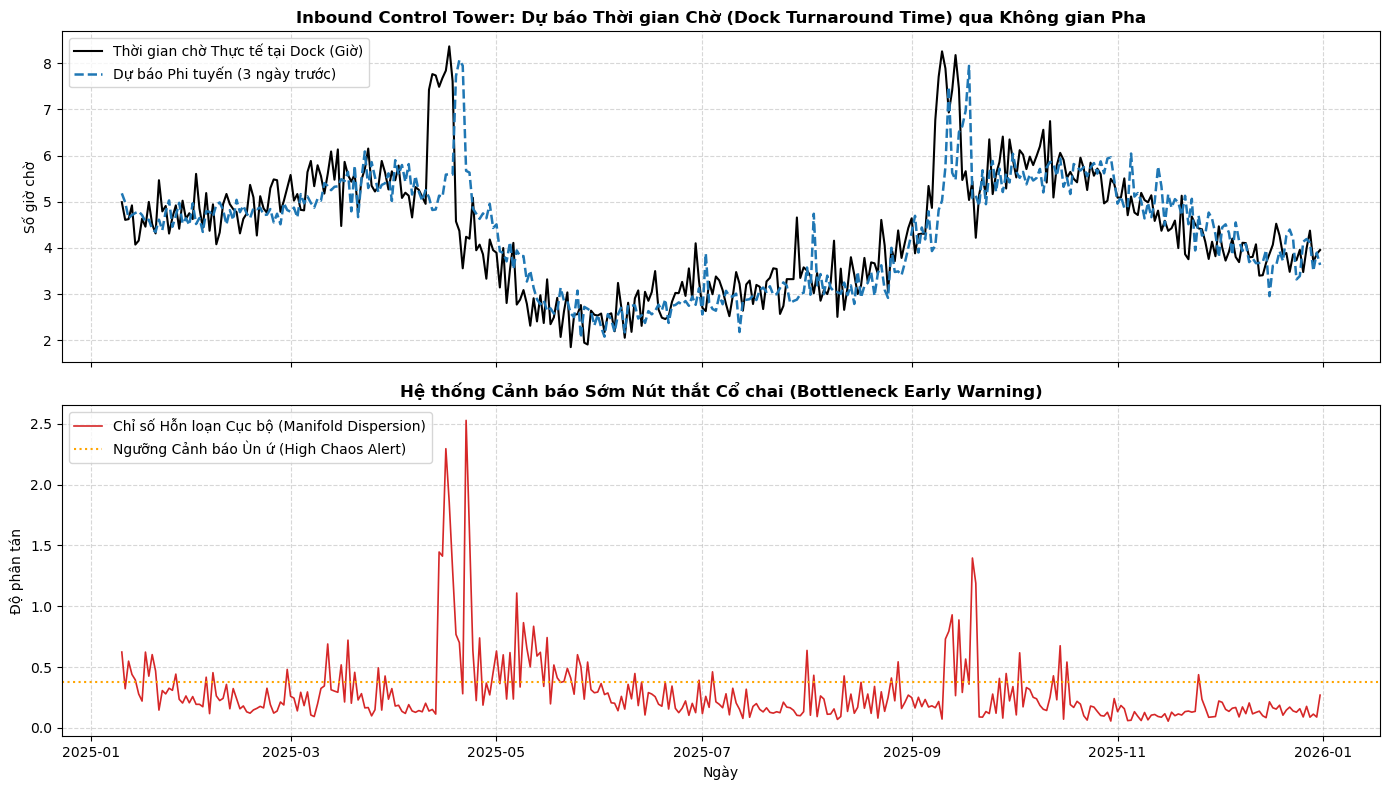

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree

# 1. Giả lập dữ liệu vận hành Inbound (Ví dụ: Thời gian chờ trung bình tại Dock trong 1 năm qua - đơn vị: giờ)
np.random.seed(42)
N_days = 365
time_index = pd.date_range(start="2025-01-01", periods=N_days, freq="D")

# Tạo chuỗi thời gian có tính chu kỳ, xu hướng và các cú sốc ngẫu nhiên (mô phỏng cao điểm lễ hội, thiếu nhân sự)
t = np.linspace(0, 50, N_days)
base_trend = 4.0 + 1.5 * np.sin(t / 5) + 0.5 * np.cos(t / 2)
shocks = np.random.normal(0, 0.4, N_days)
# Thêm vài cú sốc ùn ứ đột ngột
shocks[100:108] += 3.0
shocks[250:258] += 2.5
inbound_wait_times = np.clip(base_trend + shocks, 1.0, 15.0)

df_inbound = pd.DataFrame({"Wait_Time_Hours": inbound_wait_times}, index=time_index)
prices_vals = df_inbound["Wait_Time_Hours"].values

# 2. Cấu hình tham số Không gian Pha cho Inbound (dựa trên kết quả tối ưu trước đó: tau=2, dim=2)
tau = 2
dim = 2
forecast_horizon = 3  # Dự báo trước 3 ngày ùn ứ
N = len(prices_vals)

valid_indices = range((dim - 1) * tau, N - forecast_horizon)

# 3. Chạy mô phỏng Out-of-Sample Rolling Forecasting cho Inbound Logistics
actuals = []
preds = []
chaos_scores = []
eval_dates = []

print("Đang chạy mô phỏng dự báo Inbound Control Tower (Out-of-Sample)...")

for i in valid_indices:
  history_vals = prices_vals[: i + 1]
  if len(history_vals) < (dim - 1) * tau + 5:
    continue

  hist_valid_indices = list(range((dim - 1) * tau, len(history_vals)))
  phase_space = np.array(
      [
          [history_vals[j], history_vals[j - tau]]
          for j in hist_valid_indices
      ]
  )

  tree = KDTree(phase_space)
  current_state = np.array([history_vals[-1], history_vals[-1 - tau]])

  k_neigh = min(5, len(phase_space))
  distances, indices = tree.query(current_state, k=k_neigh)

  if np.isscalar(indices):
    indices = [indices]
    distances = [distances]

  valid_neighbors = []
  weights = []
  for d_val, n_idx in zip(distances[1:], indices[1:]):
    if n_idx < len(hist_valid_indices):
      h_pos = hist_valid_indices[n_idx]
      if h_pos < len(history_vals) - forecast_horizon:
        valid_neighbors.append(h_pos)
        weights.append(1.0 / (d_val + 1e-5))

  if len(valid_neighbors) >= 2:
    future_paths = []
    path_weights = []
    for h_pos, w in zip(valid_neighbors[:3], weights[:3]):
      path = history_vals[h_pos : h_pos + forecast_horizon + 1]
      if len(path) == forecast_horizon + 1:
        future_paths.append(path)
        path_weights.append(w)

    if future_paths:
      path_weights = np.array(path_weights)
      path_weights /= np.sum(path_weights)
      weighted_path = np.sum(
          np.array(future_paths) * path_weights[:, np.newaxis], axis=0
      )

      preds.append(weighted_path[-1])
      actuals.append(prices_vals[i + forecast_horizon])
      eval_dates.append(df_inbound.index[i + forecast_horizon])

      # Đo độ cô lập láng giềng (Chỉ số Hỗn loạn / Nguy cơ Bottleneck)
      chaos_scores.append(np.mean(distances[1:]))

# 4. Đánh giá sai số dự báo vận hành
actuals = np.array(actuals)
preds = np.array(preds)
mae = np.mean(np.abs(preds - actuals))
mape = np.mean(np.abs((actuals - preds) / (actuals + 1e-5))) * 100

print(f"\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH INBOUND CONTROL TOWER ---")
print(f"Sai số tuyệt đối trung bình (MAE thời gian chờ): {mae:.2f} giờ")
print(f"Sai số phần trăm (MAPE): {mape:.2f}%")

# 5. Trực quan hóa kết quả ứng dụng
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Biểu đồ 1: So sánh Thời gian chờ thực tế vs Dự báo của hệ thống
ax1.plot(
    eval_dates,
    actuals,
    label="Thời gian chờ Thực tế tại Dock (Giờ)",
    color="black",
    linewidth=1.5,
)
ax1.plot(
    eval_dates,
    preds,
    label="Dự báo Phi tuyến (3 ngày trước)",
    color="#1f77b4",
    linestyle="--",
    linewidth=1.8,
)
ax1.set_title(
    "Inbound Control Tower: Dự báo Thời gian Chờ (Dock Turnaround Time) qua"
    " Không gian Pha",
    fontsize=12,
    fontweight="bold",
)
ax1.set_ylabel("Số giờ chờ", fontsize=10)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Biểu đồ 2: Chỉ số Hỗn loạn / Độ phân tán Manifold (Cảnh báo sớm nút thắt cổ chai)
ax2.plot(
    eval_dates,
    chaos_scores,
    label="Chỉ số Hỗn loạn Cục bộ (Manifold Dispersion)",
    color="#d62728",
    linewidth=1.2,
)
ax2.axhline(
    y=np.percentile(chaos_scores, 80),
    color="orange",
    linestyle=":",
    label="Ngưỡng Cảnh báo Ùn ứ (High Chaos Alert)",
)
ax2.set_title(
    "Hệ thống Cảnh báo Sớm Nút thắt Cổ chai (Bottleneck Early Warning)",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Ngày", fontsize=10)
ax2.set_ylabel("Độ phân tán", fontsize=10)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

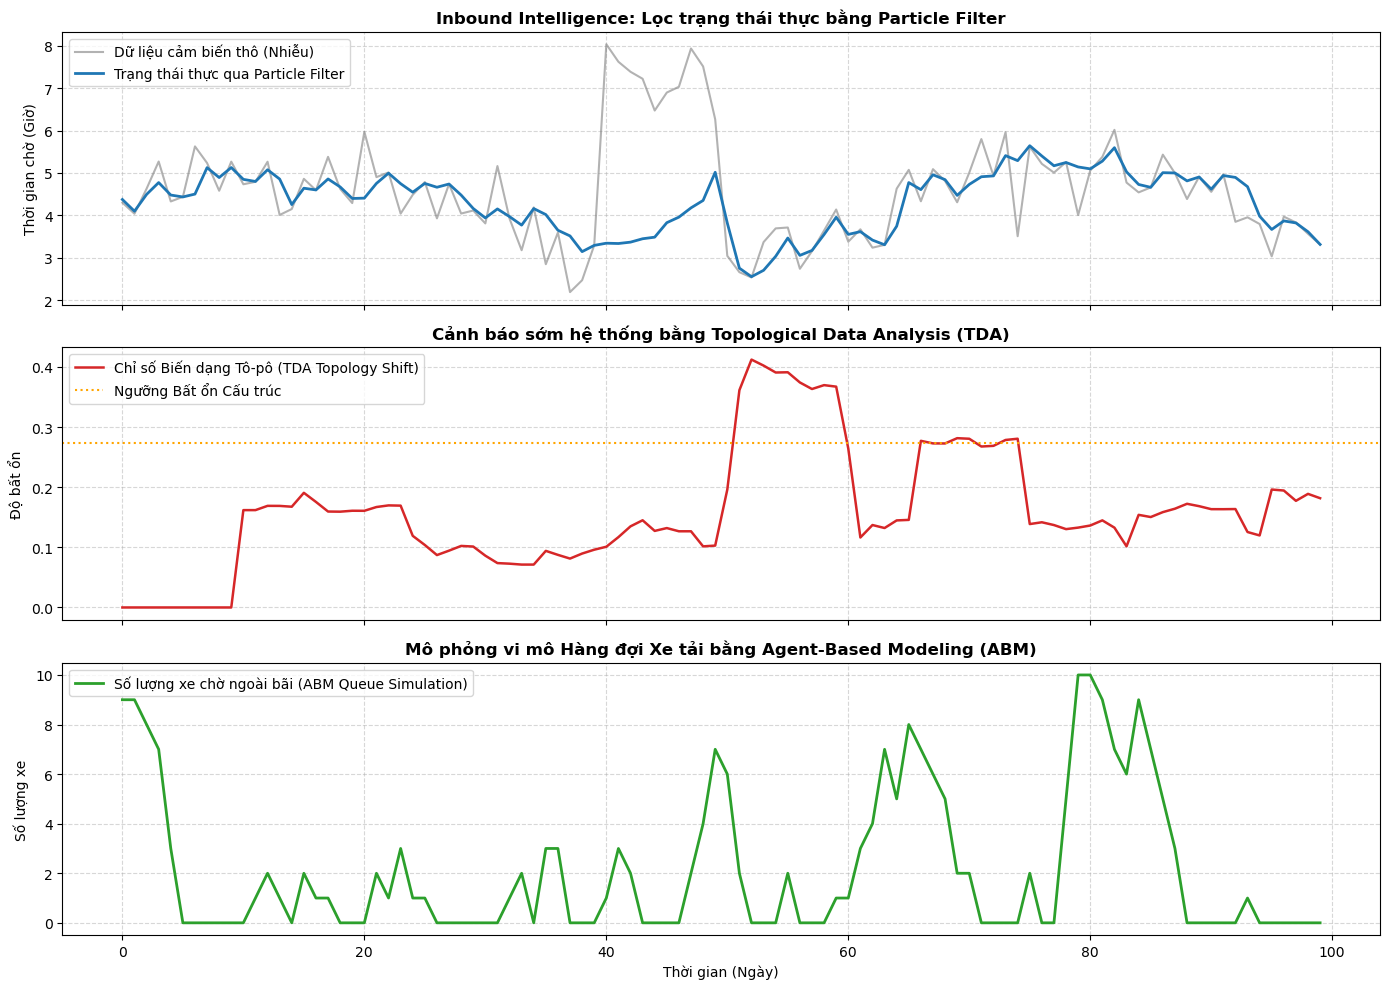

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# 1. MÔ PHỎNG DỮ LIỆU ĐẦU VÀO (INBOUND TELEMETRY)
# ==========================================
np.random.seed(42)
days = 100
time_steps = np.arange(days)

# Giả lập thời gian chờ tại dock thực tế có chứa nhiễu và cú sốc ùn ứ
true_wait_time = 4.0 + 1.2 * np.sin(time_steps / 10)
true_wait_time[40:50] += 4.5  # Cú sốc ùn tắc giữa kỳ
noisy_observations = true_wait_time + np.random.normal(
    0, 0.6, days
)  # Dữ liệu thực tế bị nhiễu cảm biến

# ==========================================
# 2. MODULE 1: PARTICLE FILTER (Lọc trạng thái thực)
# ==========================================
# Mục đích: Lọc nhiễu cảm biến để tìm ra "trạng thái ẩn thực sự" của thời gian chờ tại dock
num_particles = 100
particles = np.random.uniform(1, 10, num_particles)
weights = np.ones(num_particles) / num_particles
filtered_states = []

for obs in noisy_observations:
  # Dự đoán (Prediction step): Tiến hóa hạt với một chút nhiễu động mô hình
  particles += np.random.normal(0, 0.3, num_particles)

  # Cập nhật (Update step): Đánh trọng số dựa trên độ khớp với quan sát thực tế
  weights = 1.0 / (np.abs(particles - obs) + 1e-5)
  weights /= np.sum(weights)

  # Resampling (Lấy mẫu lại để tránh suy biến hạt)
  indices = np.random.choice(num_particles, size=num_particles, p=weights)
  particles = particles[indices]

  # Ước lượng trạng thái tối ưu (Mean of particles)
  estimated_state = np.mean(particles)
  filtered_states.append(estimated_state)

# ==========================================
# 3. MODULE 2: TDA PROXY (Phân tích biến dạng cấu trúc tô-pô)
# ==========================================
# Mục đích: Phát hiện sự thay đổi hình học / mật độ đám mây điểm (Topology Shift)
tda_anomaly_scores = []
window_tda = 10

for i in range(len(filtered_states)):
  if i < window_tda:
    tda_anomaly_scores.append(0)
    continue

  window_data = filtered_states[i - window_tda : i]
  # Đo độ tản mát cục bộ (Persistent Distance Proxy trong không gian pha 2D)
  diffs = np.abs(np.diff(window_data))
  topology_metric = np.std(diffs)  # Độ bất ổn định cấu trúc
  tda_anomaly_scores.append(topology_metric)

# ==========================================
# 4. MODULE 3: AGENT-BASED MODELING (ABM - Mô phỏng vi mô Dock & Xe tải)
# ==========================================
# Mục đích: Mô phỏng hành vi hàng đợi xe tải dựa trên trạng thái dòng chảy hiện tại
queue_lengths = []
current_queue = 5  # Số xe đang chờ ban đầu

for state in filtered_states:
  # Số lượng xe đến tỷ lệ thuận với mức độ biến động trạng thái
  trucks_arriving = np.random.poisson(max(1, int(state / 1.5)))
  # Số lượng xe được xử lý tại các cửa dock mỗi chu kỳ
  trucks_processed = np.random.randint(2, 5)

  current_queue = max(
      0, current_queue + trucks_arriving - trucks_processed
  )
  queue_lengths.append(current_queue)

# ==========================================
# 5. TRỰC QUAN HÓA KẾT QUẢ TÍCH HỢP
# ==========================================
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Biểu đồ 1: Particle Filter lọc nhiễu cảm biến
axes[0].plot(
    time_steps,
    noisy_observations,
    label="Dữ liệu cảm biến thô (Nhiễu)",
    color="gray",
    alpha=0.6,
)
axes[0].plot(
    time_steps,
    filtered_states,
    label="Trạng thái thực qua Particle Filter",
    color="#1f77b4",
    linewidth=2,
)
axes[0].set_title(
    "Inbound Intelligence: Lọc trạng thái thực bằng Particle Filter",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_ylabel("Thời gian chờ (Giờ)", fontsize=10)
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Biểu đồ 2: TDA Proxy phát hiện biến dạng cấu trúc (Cảnh báo sớm)
axes[1].plot(
    time_steps,
    tda_anomaly_scores,
    label="Chỉ số Biến dạng Tô-pô (TDA Topology Shift)",
    color="#d62728",
    linewidth=1.8,
)
axes[1].axhline(
    y=np.percentile(tda_anomaly_scores, 85),
    color="orange",
    linestyle=":",
    label="Ngưỡng Bất ổn Cấu trúc",
)
axes[1].set_title(
    "Cảnh báo sớm hệ thống bằng Topological Data Analysis (TDA)",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_ylabel("Độ bất ổn", fontsize=10)
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Biểu đồ 3: Agent-Based Modeling mô phỏng hàng đợi xe tải tại Dock
axes[2].plot(
    time_steps,
    queue_lengths,
    label="Số lượng xe chờ ngoài bãi (ABM Queue Simulation)",
    color="#2ca02c",
    linewidth=2,
)
axes[2].set_title(
    "Mô phỏng vi mô Hàng đợi Xe tải bằng Agent-Based Modeling (ABM)",
    fontsize=12,
    fontweight="bold",
)
axes[2].set_xlabel("Thời gian (Ngày)", fontsize=10)
axes[2].set_ylabel("Số lượng xe", fontsize=10)
axes[2].legend(loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá để phân tích Tô-pô (TDA)...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


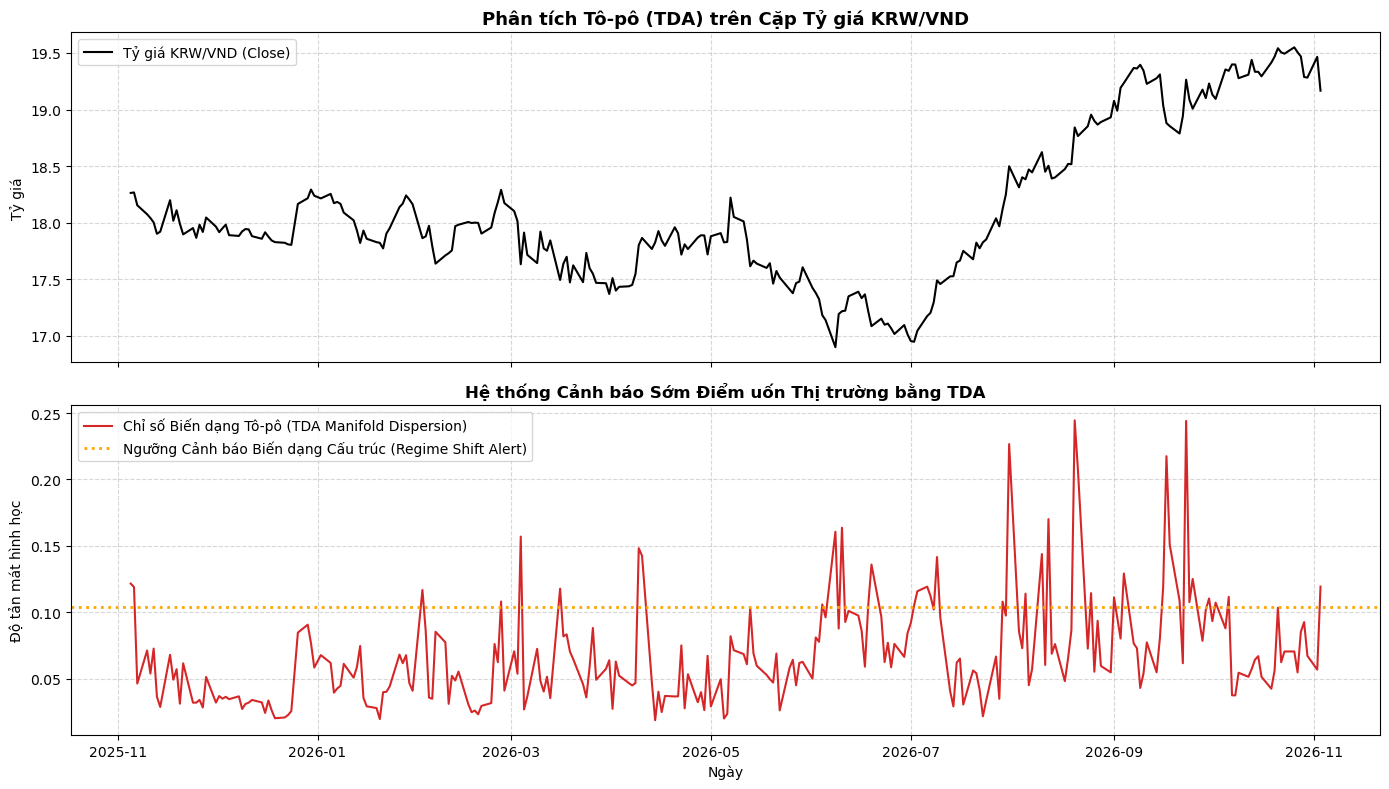

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu tỷ giá KRW/VND
print("Đang tải dữ liệu tỷ giá để phân tích Tô-pô (TDA)...")
krw_data = yf.download("KRW=X", period="1y", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="1y", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values
N = len(prices_vals)

# 2. Xây dựng Không gian Pha với tham số tối ưu (tau=2, dim=2)
tau = 2
dim = 2
valid_indices = list(range((dim - 1) * tau, N))

phase_space = np.array(
    [[prices_vals[j], prices_vals[j - tau]] for j in valid_indices]
)

# 3. Tính toán Chỉ số Biến dạng Tô-pô (Topology Shift / Manifold Dispersion Proxy)
# Đo khoảng cách trung bình đến các láng giềng gần nhất để đánh giá độ tản mát hình học cục bộ
tree = KDTree(phase_space)
tda_topology_scores = []

k_neigh = min(6, len(phase_space))
for i in range(len(phase_space)):
  current_point = phase_space[i]
  distances, _ = tree.query(current_point, k=k_neigh)
  # Lấy trung bình khoảng cách tới các láng giềng (đặc trưng cho mật độ và hình học cục bộ)
  local_dispersion = np.mean(distances[1:])
  tda_topology_scores.append(local_dispersion)

# Căn chỉnh lại ngày tháng cho khớp với biểu đồ
eval_dates = prices.index[valid_indices]
tda_topology_scores = np.array(tda_topology_scores)

# 4. Trực quan hóa kết quả TDA trên Forex
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Biểu đồ 1: Đường giá KRW/VND thực tế
ax1.plot(
    eval_dates,
    phase_space[:, 0],
    label="Tỷ giá KRW/VND (Close)",
    color="black",
    linewidth=1.5,
)
ax1.set_title(
    "Phân tích Tô-pô (TDA) trên Cặp Tỷ giá KRW/VND",
    fontsize=13,
    fontweight="bold",
)
ax1.set_ylabel("Tỷ giá", fontsize=10)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Biểu đồ 2: Chỉ số Biến dạng Tô-pô (Phát hiện điểm uốn cấu trúc thị trường)
ax2.plot(
    eval_dates,
    tda_topology_scores,
    label="Chỉ số Biến dạng Tô-pô (TDA Manifold Dispersion)",
    color="#d62728",
    linewidth=1.5,
)
anomaly_threshold = np.percentile(tda_topology_scores, 85)
ax2.axhline(
    y=anomaly_threshold,
    color="orange",
    linestyle=":",
    linewidth=2,
    label="Ngưỡng Cảnh báo Biến dạng Cấu trúc (Regime Shift Alert)",
)
ax2.set_title(
    "Hệ thống Cảnh báo Sớm Điểm uốn Thị trường bằng TDA",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Ngày", fontsize=10)
ax2.set_ylabel("Độ tản mát hình học", fontsize=10)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu mới nhất đến thời điểm hiện tại
print("Đang tải dữ liệu thời gian thực để dự báo tương lai...")
krw_data = yf.download("KRW=X", period="max", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="max", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values

# 2. Cài đặt tham số tối ưu đã kiểm chứng
tau = 2
dim = 2
forecast_horizon = 5  # Dự báo 5 ngày tới

# 3. Xây dựng không gian pha từ toàn bộ lịch sử đến nay
hist_valid_indices = list(range((dim - 1) * tau, len(prices_vals)))
phase_space = np.array(
    [[prices_vals[j], prices_vals[j - tau]] for j in hist_valid_indices]
)

tree = KDTree(phase_space)

# Lấy trạng thái của ngày giao dịch mới nhất hôm nay
current_state = np.array([prices_vals[-1], prices_vals[-1 - tau]])

# 4. Tìm các láng giềng trong quá khứ có hình thái giống hệt hiện tại nhất
k_neighbors = 6
distances, indices = tree.query(current_state, k=k_neighbors)

valid_neighbors = []
weights = []
for d_val, n_idx in zip(distances[1:], indices[1:]):
  if n_idx < len(hist_valid_indices):
    h_pos = hist_valid_indices[n_idx]
    # Đảm bảo láng giềng có đủ dữ liệu 5 ngày tiếp theo để ngoại suy
    if h_pos < len(prices_vals) - forecast_horizon:
      valid_neighbors.append(h_pos)
      weights.append(1.0 / (d_val + 1e-5))

# 5. Ngoại suy quỹ đạo tương lai dựa trên trung bình có trọng số của các láng giềng
print(f"\n--- KẾT QUẢ DỰ BÁO TƯƠNG LAI (5 NGÀY TỚI) ---")
print(f"Mốc giá hiện tại gần nhất: {prices_vals[-1]:.4f} ({prices.index[-1].strftime('%Y-%m-%d')})")

if len(valid_neighbors) >= 2:
  future_paths = []
  path_weights = []
  for h_pos, w in zip(valid_neighbors[:3], weights[:3]):
    # Lấy chuỗi giá 5 ngày tiếp theo từ thời điểm quá khứ tương đồng đó
    path = prices_vals[h_pos : h_pos + forecast_horizon + 1]
    if len(path) == forecast_horizon + 1:
      future_paths.append(path)
      path_weights.append(w)

  if future_paths:
    path_weights = np.array(path_weights)
    path_weights /= np.sum(path_weights)
    predicted_path = np.sum(
        np.array(future_paths) * path_weights[:, np.newaxis], axis=0
    )

    # In ra giá trị dự báo cho từng ngày trong tương lai
    future_dates = pd.bdate_range(
        start=prices.index[-1] + pd.Timedelta(days=1), periods=forecast_horizon
    )
    for i, (d, p) in enumerate(zip(future_dates, predicted_path[1:])):
      change_pct = ((p - prices_vals[-1]) / prices_vals[-1]) * 100
      print(
          f"Ngày {d.strftime('%Y-%m-%d')} (+{i+1} ngày): {p:.4f}"
          f" (Biên độ so với hiện tại: {change_pct:+.2f}%)"
      )
else:
  print("Không tìm thấy đủ láng giềng tương thích để dự báo.")

Đang tải dữ liệu thời gian thực để dự báo tương lai...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


--- KẾT QUẢ DỰ BÁO TƯƠNG LAI (5 NGÀY TỚI) ---
Mốc giá hiện tại gần nhất: 19.1691 (2026-11-03)
Ngày 2026-11-04 (+1 ngày): 19.0327 (Biên độ so với hiện tại: -0.71%)
Ngày 2026-11-05 (+2 ngày): 19.0922 (Biên độ so với hiện tại: -0.40%)
Ngày 2026-11-06 (+3 ngày): 18.9170 (Biên độ so với hiện tại: -1.32%)
Ngày 2026-11-09 (+4 ngày): 19.0792 (Biên độ so với hiện tại: -0.47%)
Ngày 2026-11-10 (+5 ngày): 19.1404 (Biên độ so với hiện tại: -0.15%)


Đang tải dữ liệu thời gian thực để dự báo tương lai...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed



--- KẾT QUẢ DỰ BÁO TƯƠNG LAI (5 NGÀY TỚI) ---
Mốc giá hiện tại gần nhất: 19.1681 (2026-11-03)
Ngày 2026-11-04 (+1 ngày): 19.0420 (Biên độ so với hiện tại: -0.66%)
Ngày 2026-11-05 (+2 ngày): 19.0954 (Biên độ so với hiện tại: -0.38%)
Ngày 2026-11-06 (+3 ngày): 18.9080 (Biên độ so với hiện tại: -1.36%)
Ngày 2026-11-09 (+4 ngày): 19.0781 (Biên độ so với hiện tại: -0.47%)
Ngày 2026-11-10 (+5 ngày): 19.1325 (Biên độ so với hiện tại: -0.19%)


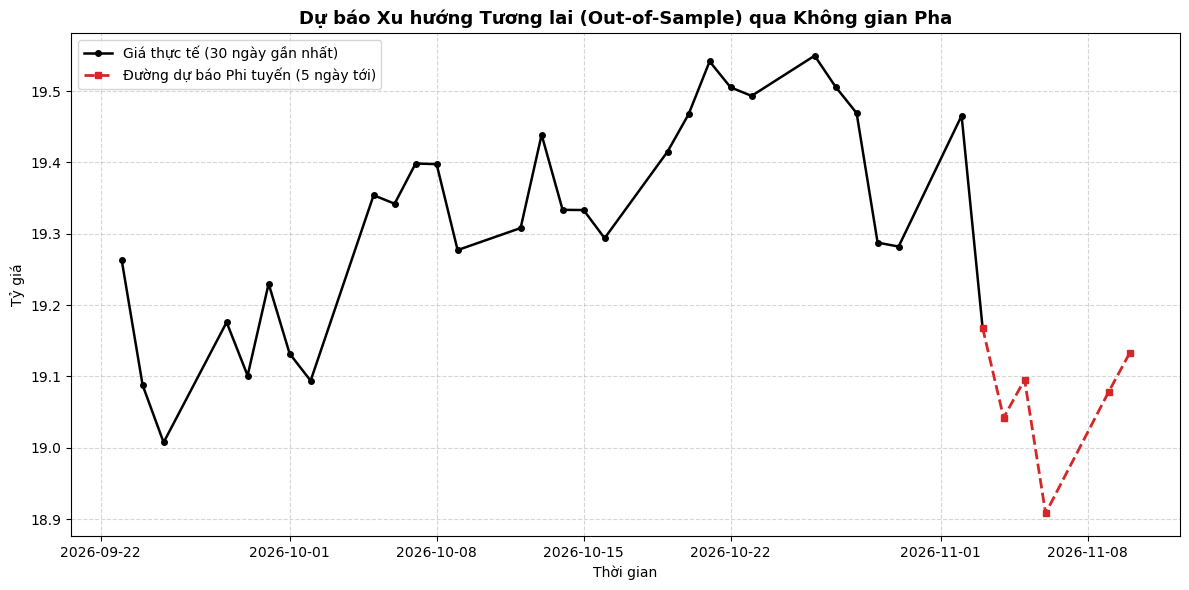

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial import KDTree
import yfinance as yf

# 1. Tải dữ liệu mới nhất đến thời điểm hiện tại
print("Đang tải dữ liệu thời gian thực để dự báo tương lai...")
krw_data = yf.download("KRW=X", period="max", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="max", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()
prices_vals = prices.values

# 2. Cài đặt tham số tối ưu đã kiểm chứng
tau = 2
dim = 2
forecast_horizon = 5  # Dự báo 5 ngày tới

# 3. Xây dựng không gian pha từ toàn bộ lịch sử đến nay
hist_valid_indices = list(range((dim - 1) * tau, len(prices_vals)))
phase_space = np.array(
    [[prices_vals[j], prices_vals[j - tau]] for j in hist_valid_indices]
)

tree = KDTree(phase_space)

# Lấy trạng thái của ngày giao dịch mới nhất hôm nay
current_state = np.array([prices_vals[-1], prices_vals[-1 - tau]])

# 4. Tìm các láng giềng trong quá khứ có hình thái giống hệt hiện tại nhất
k_neighbors = 6
distances, indices = tree.query(current_state, k=k_neighbors)

valid_neighbors = []
weights = []
for d_val, n_idx in zip(distances[1:], indices[1:]):
  if n_idx < len(hist_valid_indices):
    h_pos = hist_valid_indices[n_idx]
    if h_pos < len(prices_vals) - forecast_horizon:
      valid_neighbors.append(h_pos)
      weights.append(1.0 / (d_val + 1e-5))

# 5. Ngoại suy quỹ đạo tương lai và chuẩn bị dữ liệu vẽ hình
print(f"\n--- KẾT QUẢ DỰ BÁO TƯƠNG LAI (5 NGÀY TỚI) ---")
print(f"Mốc giá hiện tại gần nhất: {prices_vals[-1]:.4f} ({prices.index[-1].strftime('%Y-%m-%d')})")

predicted_prices = []
future_dates = pd.bdate_range(
    start=prices.index[-1] + pd.Timedelta(days=1), periods=forecast_horizon
)

if len(valid_neighbors) >= 2:
  future_paths = []
  path_weights = []
  for h_pos, w in zip(valid_neighbors[:3], weights[:3]):
    path = prices_vals[h_pos : h_pos + forecast_horizon + 1]
    if len(path) == forecast_horizon + 1:
      future_paths.append(path)
      path_weights.append(w)

  if future_paths:
    path_weights = np.array(path_weights)
    path_weights /= np.sum(path_weights)
    predicted_path = np.sum(
        np.array(future_paths) * path_weights[:, np.newaxis], axis=0
    )

    # Lấy giá trị dự báo (bỏ qua điểm gốc trùng với hiện tại)
    predicted_prices = predicted_path[1:]

    for i, (d, p) in enumerate(zip(future_dates, predicted_prices)):
      change_pct = ((p - prices_vals[-1]) / prices_vals[-1]) * 100
      print(
          f"Ngày {d.strftime('%Y-%m-%d')} (+{i+1} ngày): {p:.4f}"
          f" (Biên độ so với hiện tại: {change_pct:+.2f}%)"
      )

    # ==========================================
    # 6. VẼ ĐỒ THỊ TRỰC QUAN HÓA KẾT QUẢ DỰ BÁO
    # ==========================================
    plt.figure(figsize=(12, 6))

    # Lấy 30 ngày gần nhất của lịch sử để phóng to khung hình cho dễ nhìn
    recent_dates = prices.index[-30:]
    recent_vals = prices_vals[-30:]

    # Vẽ đường giá thực tế gần đây
    plt.plot(
        recent_dates,
        recent_vals,
        label="Giá thực tế (30 ngày gần nhất)",
        color="black",
        linewidth=1.8,
        marker="o",
        markersize=4,
    )

    # Nối điểm cuối cùng của thực tế với đường dự báo để liền mạch biểu đồ
    bridge_dates = [prices.index[-1]] + list(future_dates)
    bridge_vals = [prices_vals[-1]] + list(predicted_prices)

    plt.plot(
        bridge_dates,
        bridge_vals,
        label="Đường dự báo Phi tuyến (5 ngày tới)",
        color="#d62728",
        linestyle="--",
        linewidth=2,
        marker="s",
        markersize=5,
    )

    plt.title(
        "Dự báo Xu hướng Tương lai (Out-of-Sample) qua Không gian Pha",
        fontsize=13,
        fontweight="bold",
    )
    plt.xlabel("Thời gian", fontsize=10)
    plt.ylabel("Tỷ giá", fontsize=10)
    plt.legend(loc="upper left")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

else:
  print("Không tìm thấy đủ láng giềng tương thích để dự báo.")

Đang tải dữ liệu tỷ giá KRW/VND...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Mốc giao dịch được chọn cho ngày 2026-06-15: 2026-06-15


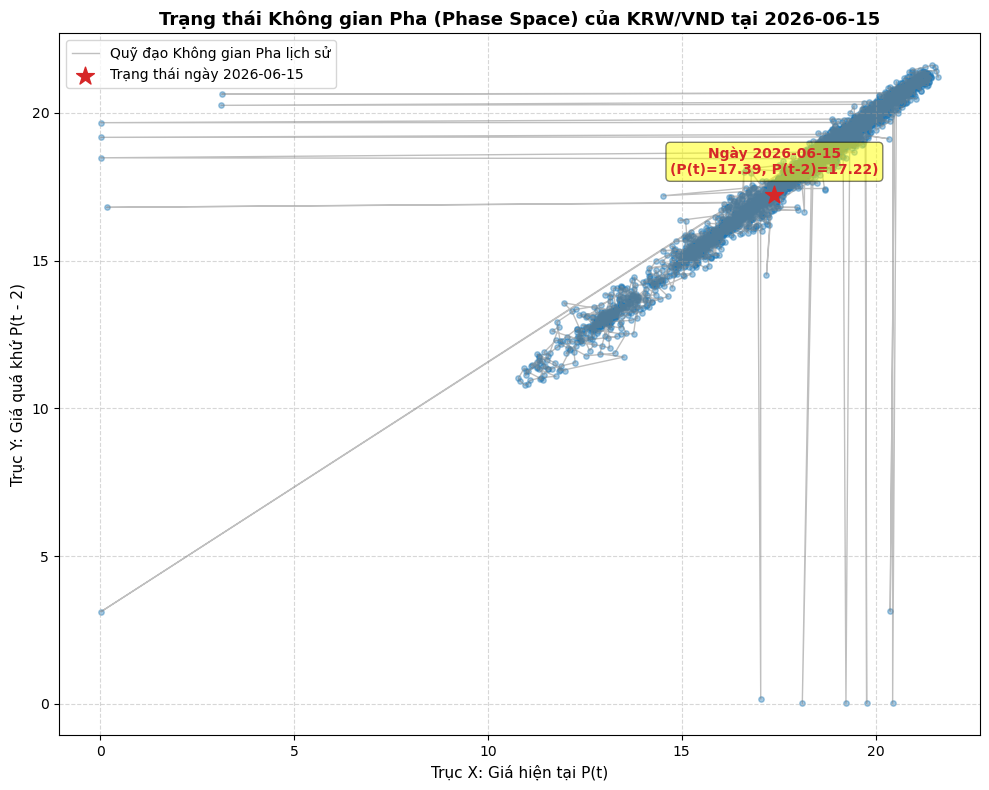

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Tải dữ liệu tỷ giá
print("Đang tải dữ liệu tỷ giá KRW/VND...")
krw_data = yf.download("KRW=X", period="max", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="max", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()

# 2. Xác định mốc thời gian mục tiêu: ngày 15 tháng 6 năm 2026
target_date_str = "2026-06-15"
target_ts = pd.Timestamp(target_date_str)

# Cắt dữ liệu đến đúng ngày mục tiêu (hoặc ngày giao dịch gần nhất trước đó nếu ngày 15/6 là ngày nghỉ)
prices_filtered = prices.loc[:target_ts]
if prices_filtered.empty:
  raise ValueError("Không có dữ liệu trước ngày mục tiêu!")

actual_date = prices_filtered.index[-1]
print(
    f"Mốc giao dịch được chọn cho ngày {target_date_str}:"
    f" {actual_date.strftime('%Y-%m-%d')}"
)

prices_vals = prices_filtered.values
dates = prices_filtered.index

# 3. Xây dựng Không gian Pha (Takens' Embedding: dim=2, tau=2)
tau = 2
dim = 2
valid_indices = list(range((dim - 1) * tau, len(prices_vals)))
phase_space = np.array(
    [[prices_vals[j], prices_vals[j - tau]] for j in valid_indices]
)
phase_dates = dates[valid_indices]

# Tìm vị trí index của ngày mục tiêu trong không gian pha
target_mask = phase_dates == actual_date
target_indices = np.where(target_mask)[0]

# 4. Trực quan hóa Không gian Pha và chấm đỏ điểm ngày 15/06/2026
plt.figure(figsize=(10, 8))

# Vẽ toàn bộ quỹ đạo không gian pha lịch sử tính đến thời điểm đó
plt.plot(
    phase_space[:, 0],
    phase_space[:, 1],
    color="gray",
    alpha=0.5,
    linewidth=1,
    label="Quỹ đạo Không gian Pha lịch sử",
)
plt.scatter(
    phase_space[:, 0],
    phase_space[:, 1],
    color="#1f77b4",
    alpha=0.4,
    s=15,
)

# Đánh dấu điểm trạng thái tại ngày 15/06/2026
if len(target_indices) > 0:
  t_idx = target_indices[0]
  target_point = phase_space[t_idx]

  plt.scatter(
      [target_point[0]],
      [target_point[1]],
      color="#d62728",
      s=180,
      zorder=5,
      marker="*",
      label=f"Trạng thái ngày {actual_date.strftime('%Y-%m-%d')}",
  )
  plt.annotate(
      f"Ngày {actual_date.strftime('%Y-%m-%d')}\n(P(t)={target_point[0]:.2f},"
      f" P(t-2)={target_point[1]:.2f})",
      (target_point[0], target_point[1]),
      textcoords="offset points",
      xytext=(0, 15),
      ha="center",
      fontweight="bold",
      color="#d62728",
      bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.5),
  )

plt.title(
    f"Trạng thái Không gian Pha (Phase Space) của KRW/VND tại"
    f" {actual_date.strftime('%Y-%m-%d')}",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Trục X: Giá hiện tại P(t)", fontsize=11)
plt.ylabel(f"Trục Y: Giá quá khứ P(t - {tau})", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

Đang tải dữ liệu tỷ giá từ yfinance...


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


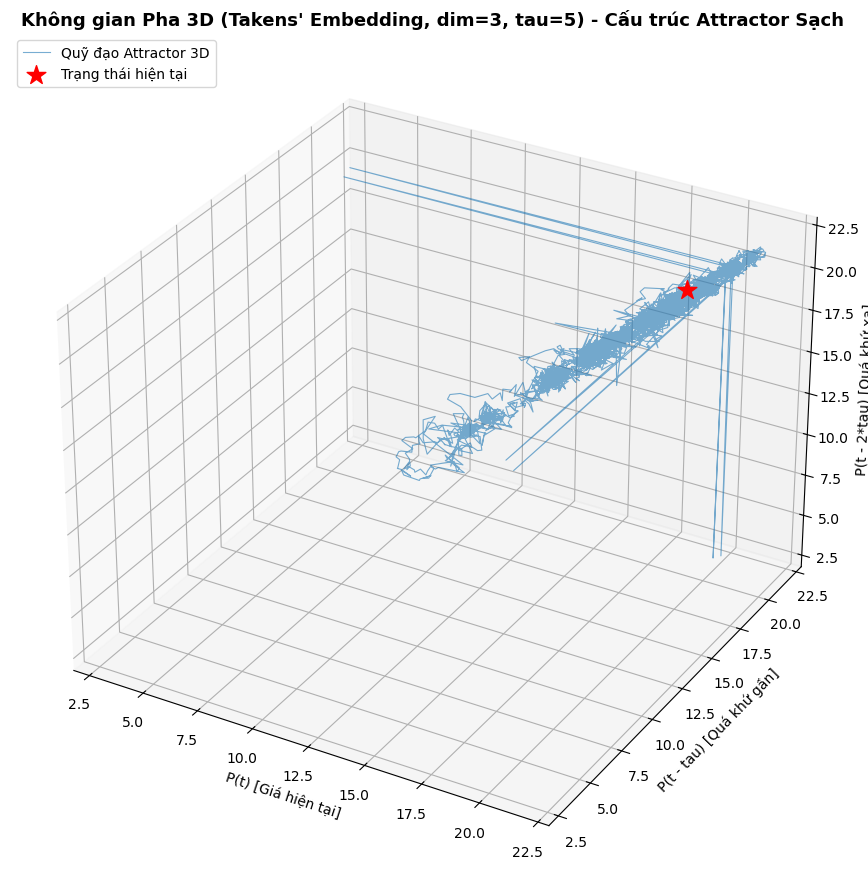

In [21]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Tải dữ liệu tỷ giá trực tiếp
print("Đang tải dữ liệu tỷ giá từ yfinance...")
krw_data = yf.download("KRW=X", period="max", interval="1d", auto_adjust=True)
vnd_data = yf.download("VND=X", period="max", interval="1d", auto_adjust=True)


def get_close(df):
  if isinstance(df.columns, pd.MultiIndex):
    return df["Close"].iloc[:, 0]
  return df["Close"]


prices = (get_close(vnd_data) / get_close(krw_data)).dropna()

# 2. Làm sạch dữ liệu: loại bỏ các giá trị ngoại lệ, lỗi hiển thị hoặc bằng 0
prices = prices[(prices > 1.0) & (prices < 100.0)]
prices_vals = prices.values

# 3. Xây dựng Không gian Pha 3D (Takens' Embedding: dim=3, tau=5)
tau = 5
dim = 3
valid_indices = list(range((dim - 1) * tau, len(prices_vals)))
phase_space = np.array(
    [
        [prices_vals[j], prices_vals[j - tau], prices_vals[j - 2 * tau]]
        for j in valid_indices
    ]
)

# 4. Vẽ đồ thị 3D Không gian Pha (Attractor) tương tác
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

# Vẽ đường quỹ đạo không gian pha lịch sử
ax.plot(
    phase_space[:, 0],
    phase_space[:, 1],
    phase_space[:, 2],
    color="#1f77b4",
    alpha=0.6,
    linewidth=0.8,
    label="Quỹ đạo Attractor 3D",
)

# Đánh dấu điểm trạng thái mới nhất (hiện tại) bằng ngôi sao đỏ
ax.scatter(
    phase_space[-1, 0],
    phase_space[-1, 1],
    phase_space[-1, 2],
    color="red",
    s=200,
    marker="*",
    label="Trạng thái hiện tại",
)

# Thiết lập giao diện biểu đồ
ax.set_title(
    "Không gian Pha 3D (Takens' Embedding, dim=3, tau=5) - Cấu trúc Attractor"
    " Sạch",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("P(t) [Giá hiện tại]", fontsize=10)
ax.set_ylabel("P(t - tau) [Quá khứ gần]", fontsize=10)
ax.set_zlabel("P(t - 2*tau) [Quá khứ xa]", fontsize=10)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()